In [32]:
import pandas as pd
df = pd.read_csv("human_activity_recognition.csv")

In [33]:
df.shape

(10299, 565)

In [34]:
df.describe()

,subject_id,activity_id,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
count,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,...,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000,10299.000000
mean,16.146422,3.624624,0.274347,-0.017743,-0.108925,-0.607784,-0.510191,-0.613064,-0.633593,-0.525697,...,0.126708,-0.298592,-0.617700,0.007705,0.002648,0.017683,-0.009219,-0.496522,0.063255,-0.054284
std,8.679067,1.743695,0.067628,0.037128,0.053033,0.438694,0.500240,0.403657,0.413333,0.484201,...,0.245443,0.320199,0.308796,0.336591,0.447364,0.616188,0.484770,0.511158,0.305468,0.268898
min,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,9.000000,2.000000,0.262625,-0.024902,-0.121019,-0.992360,-0.976990,-0.979137,-0.993293,-0.977017,...,-0.019481,-0.536174,-0.841847,-0.124694,-0.287031,-0.493108,-0.389041,-0.817288,0.002151,-0.131880
50%,17.000000,4.000000,0.277174,-0.017162,-0.108596,-0.943030,-0.835032,-0.850773,-0.948244,-0.843670,...,0.136245,-0.335160,-0.703402,0.008146,0.007668,0.017192,-0.007186,-0.715631,0.182028,-0.003882
75%,24.000000,5.000000,0.288354,-0.010625,-0.097589,-0.250293,-0.057336,-0.278737,-0.302033,-0.087405,...,0.288960,-0.113167,-0.487981,0.149005,0.291490,0.536137,0.365996,-0.521503,0.250790,0.102970
max,30.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
df.isnull().sum()

subject_id                              0
activity_id                             0
activity                                0
dataset_split                           0
tBodyAcc-mean()-X                       0
                                       ..
angle(tBodyGyroMean,gravityMean)        0
angle(tBodyGyroJerkMean,gravityMean)    0
angle(X,gravityMean)                    0
angle(Y,gravityMean)                    0
angle(Z,gravityMean)                    0
Length: 565, dtype: int64

In [37]:
df.columns

Index(['subject_id', 'activity_id', 'activity', 'dataset_split',
       'tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
       'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       ...
       'fBodyBodyGyroJerkMag-meanFreq()', 'fBodyBodyGyroJerkMag-skewness()',
       'fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)',
       'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)'],
      dtype='object', length=565)

In [38]:
df.dtypes

subject_id                                int64
activity_id                               int64
activity                                 object
dataset_split                            object
tBodyAcc-mean()-X                       float64
                                         ...   
angle(tBodyGyroMean,gravityMean)        float64
angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Length: 565, dtype: object

In [39]:
meta_cols = ["subject_id", "activity_id", "activity", "dataset_split"]

X = df.drop(columns=meta_cols)   # only the 561 sensor features
y = df["activity"]               # what the model predicts

print(X.shape)   

(10299, 561)


Last columns in the file: ['angle(tBodyGyroMean,gravityMean)', 'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)', 'angle(Y,gravityMean)', 'angle(Z,gravityMean)']

Outlier % per feature (summary):
count    561.000000
mean       3.884045
std        5.370793
min        0.000000
25%        0.242742
50%        1.155452
75%        6.796776
max       37.586173
dtype: float64

Features with the most outliers:
tBodyAccJerk-mean()-X     37.586173
tBodyGyro-mean()-X        31.944849
tBodyGyroJerk-mean()-X    30.566074
tBodyAccJerk-mean()-Y     29.750461
tBodyGyroJerk-mean()-Y    29.595106
tBodyAccJerk-mean()-Z     26.963783
tBodyGyroJerk-mean()-Z    26.565686
tBodyGyro-mean()-Y        23.944072
tBodyAcc-mean()-X         23.662492
tBodyGyro-mean()-Z        21.730265
dtype: float64


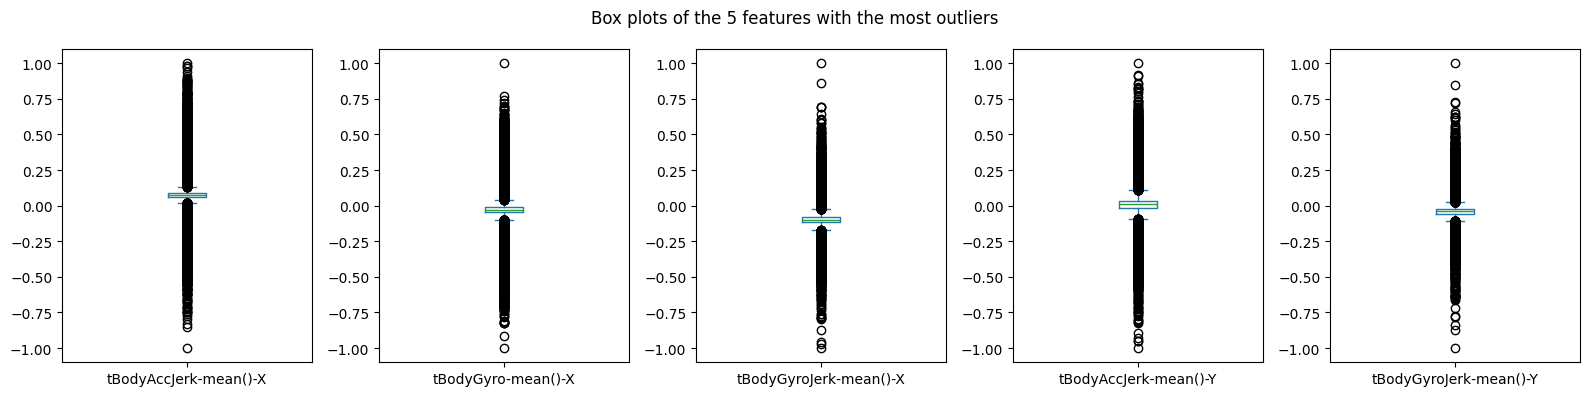


Skewness summary:
count    561.000000
mean       1.637098
std        2.284569
min       -3.490402
25%        0.154835
50%        0.869029
75%        2.403208
max       14.029486
dtype: float64
Features with |skew| < 0.5 (roughly symmetric): 165 of 561


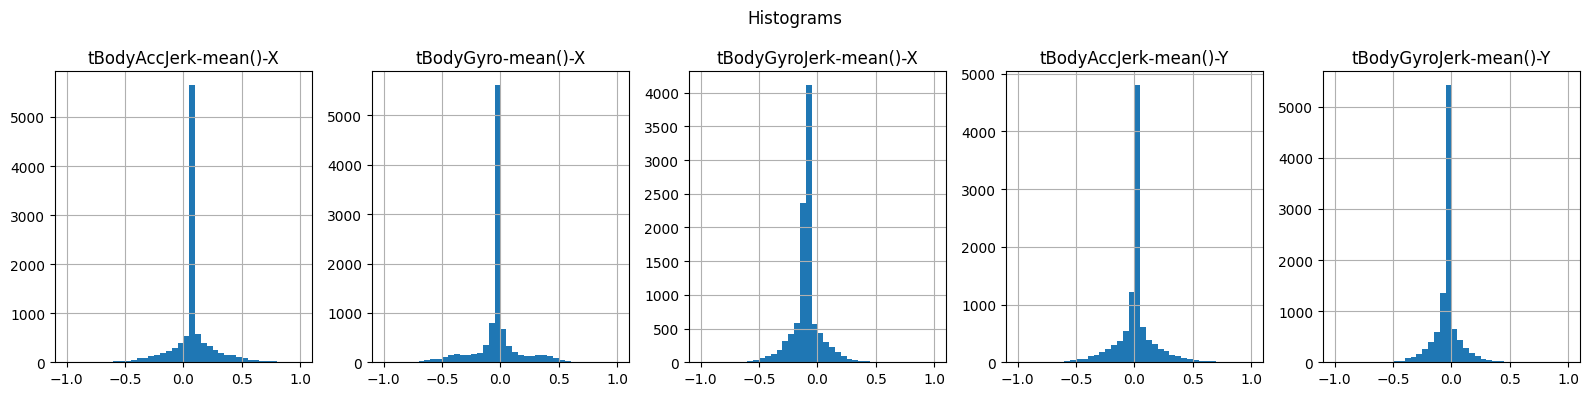

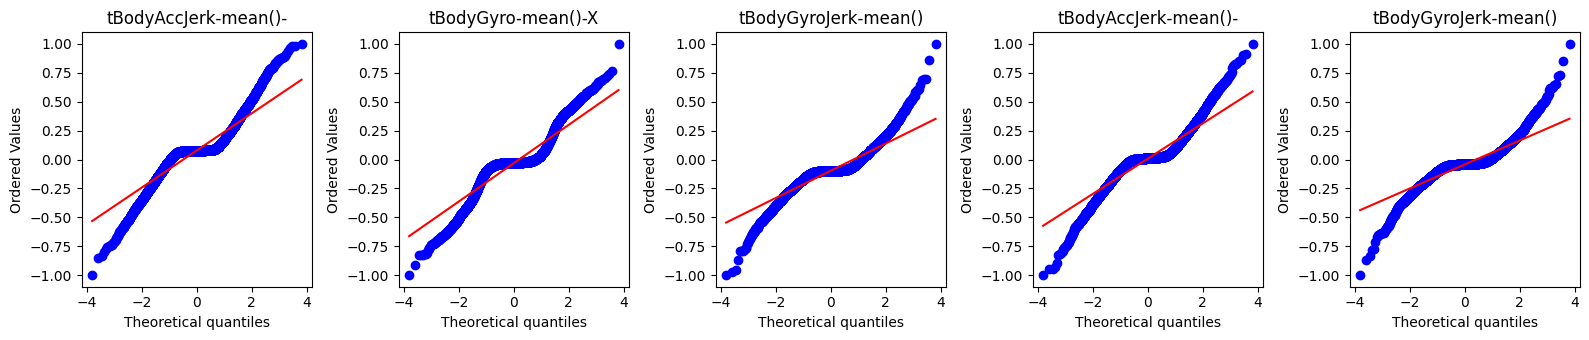


Shapiro-Wilk test:
tBodyAccJerk-mean()-X: p = 0.0000 (not normal)
tBodyGyro-mean()-X: p = 0.0000 (not normal)
tBodyGyroJerk-mean()-X: p = 0.0000 (not normal)
tBodyAccJerk-mean()-Y: p = 0.0000 (not normal)
tBodyGyroJerk-mean()-Y: p = 0.0000 (not normal)


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ---------- Load the data ----------
df = pd.read_csv("human_activity_recognition.csv")
print("Last columns in the file:", list(df.columns[-5:]))

# ---------- Outliers (IQR rule) ----------
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
is_outlier = (X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)
outlier_pct = is_outlier.mean() * 100   # % of rows flagged, per feature

print("\nOutlier % per feature (summary):")
print(outlier_pct.describe())
print("\nFeatures with the most outliers:")
print(outlier_pct.sort_values(ascending=False).head(10))

# the 5 features with the most outliers
look_at = outlier_pct.sort_values(ascending=False).head(5).index

# box plots
X[look_at].plot(kind="box", subplots=True, layout=(1, 5), figsize=(16, 4))
plt.suptitle("Box plots of the 5 features with the most outliers")
plt.tight_layout()
plt.show()

# ---------- Normality ----------
skewness = X.skew()
print("\nSkewness summary:")
print(skewness.describe())
print("Features with |skew| < 0.5 (roughly symmetric):",
      (skewness.abs() < 0.5).sum(), "of", len(skewness))

# histograms
X[look_at].hist(bins=40, figsize=(16, 4), layout=(1, 5))
plt.suptitle("Histograms")
plt.tight_layout()
plt.show()

# Q-Q plots (dots on the line = close to normal)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, col in zip(axes, look_at):
    stats.probplot(X[col], dist="norm", plot=ax)
    ax.set_title(col[:20])
plt.tight_layout()
plt.show()

# Shapiro-Wilk test on a random sample of 1000 rows
sample = X[look_at].sample(1000, random_state=42)
print("\nShapiro-Wilk test:")
for col in look_at:
    stat, p = stats.shapiro(sample[col])
    print(f"{col}: p = {p:.4f}", "(not normal)" if p < 0.05 else "(looks normal)")

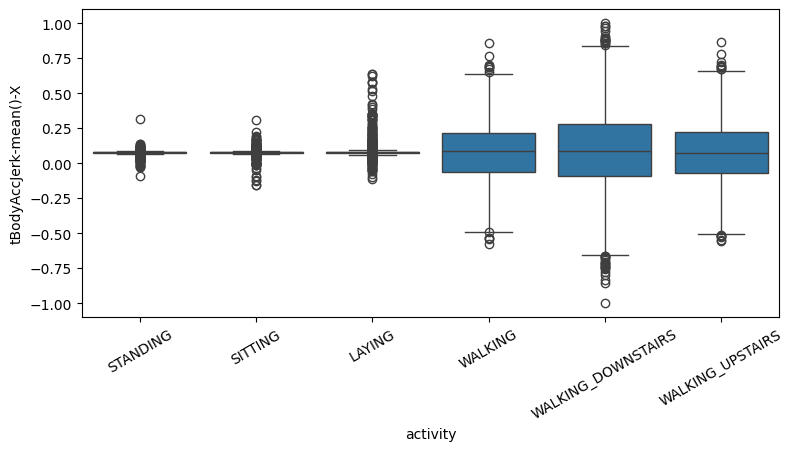

In [41]:
import seaborn as sns
col = "tBodyAccJerk-mean()-X"
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="activity", y=col)
plt.xticks(rotation=30)
plt.show()

In [42]:
print(X.shape)
print([c for c in X.columns if "subject" in c or "activity" in c or "split" in c])

(10299, 561)
[]
